In [1]:
import plotly 
import kaleido  
import IPython 
import pandas as pd

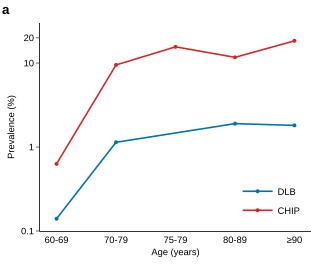

In [2]:
import numpy as np
import plotly.graph_objects as go

FONT = "Arial"
TEXT_PT, AXIS_PT, LETTER_PT = 7.0, 7.0, 10.0
AXIS_LINE_PT, TICK_LENGTH_PT = 0.6, 2.5

PT_MM_ = globals().get("PT_MM", 25.4 / 72)
U_ = globals().get("U", 96 / 25.4)
HEADER_MM = globals().get("HEADER", 6.0)

TEXT = TEXT_PT * PT_MM_ * U_
AXIS_TEXT = AXIS_PT * PT_MM_ * U_
LETTER = LETTER_PT * PT_MM_ * U_
AXIS_LINE = AXIS_LINE_PT * PT_MM_ * U_
TICK_LENGTH = TICK_LENGTH_PT * PT_MM_ * U_

W_MM, H_MM = 170.0 / 2, 70.0
W, H = round(W_MM * U_), round(H_MM * U_)
ML, MR, MT, MB = 40, 10, round(HEADER_MM * U_), 34

ages = ["60-69", "70-79", "75-79", "80-89", "≥90"]
dlb = [0.14, 1.14, None, 1.9, 1.81]
chip = [0.63, 9.5, 15.6, 11.7, 18.4]

fig = go.Figure()
for name, y, col in [("DLB", dlb, "#0072B2"), ("CHIP", chip, "#D62728")]:
    fig.add_trace(go.Scatter(
        x=ages, y=y, name=name, mode="lines+markers", connectgaps=True,
        line=dict(color=col, width=AXIS_LINE * 2), marker=dict(color=col, size=4),
        hoverinfo="skip",
    ))

pw, ph = W - ML - MR, H - MT - MB

fig.update_layout(
    width=W, height=H, title=None,
    font=dict(family=FONT, size=TEXT, color="black"),
    paper_bgcolor="white", plot_bgcolor="white",
    margin=dict(l=ML, r=MR, t=MT, b=MB),
    showlegend=True,
    legend=dict(x=0.98, y=0.03, xanchor="right", yanchor="bottom",
                bgcolor="rgba(0,0,0,0)", borderwidth=0,
                itemwidth=30, tracegroupgap=0,
                font=dict(family=FONT, size=TEXT)),
    hovermode=False, dragmode=False,
    annotations=[dict(
        text="<b>a</b>", xref="paper", yref="paper",
        x=-ML / pw, y=1 + MT / ph, xanchor="left", yanchor="top",
        showarrow=False, font=dict(family=FONT, size=LETTER, color="black"),
    )],
)

common = dict(
    showline=True, linecolor="black", linewidth=AXIS_LINE,
    tickwidth=AXIS_LINE, ticklen=TICK_LENGTH, showgrid=False, fixedrange=True,
    title_standoff=4,
    title_font=dict(family=FONT, size=AXIS_TEXT, color="black"),
    tickfont=dict(family=FONT, size=TEXT, color="black"),
)

fig.update_xaxes(title_text="Age (years)", type="category",
                 categoryorder="array", categoryarray=ages, ticks="", **common)
fig.update_yaxes(title_text="Prevalence (%)", type="log",
                 range=[np.log10(0.1), np.log10(30)],
                 tickvals=[0.1, 1, 10, 20], ticktext=["0.1", "1", "10", "20"],
                 ticks="outside", **common)

try:
    from IPython.display import display, SVG
    display(SVG(data=fig.to_image(format="svg")))
except Exception:
    fig.show(config={"staticPlot": True, "displayModeBar": False})

In [20]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from scipy.stats import gaussian_kde

FONT, PT, LETTER_PT = "Arial", 7.0, 10.0
PT_MM_ = globals().get("PT_MM", 25.4 / 72)
U_ = globals().get("U", 96 / 25.4)
px = lambda pt: pt * PT_MM_ * U_

LINE, TICK, TEXT, LETTER = px(0.6), px(2.5), px(PT), px(LETTER_PT)
W, H = round(85 * U_), round(70 * U_)
ML, MR, MT, MB = 40, 10, round(globals().get("HEADER", 6.0) * U_), 34

path = "/mnt/claw-raid/elliot/P001_CHIP/Data/processed/Pathology/Pathology plots csvs.csv"
df = pd.read_csv(path)
df["CHIP"] = df["CHIP"].str.strip()

xgrid = np.linspace(55, 105, 300)
fig = go.Figure()
for k, lab, col in [("N", "CHIP-", "#7F7F7F"), ("Y", "CHIP+", "#D62728")]:
    a = df.loc[df.CHIP == k, "Age"].to_numpy()
    fig.add_trace(go.Histogram(
        x=a, histnorm="probability density", opacity=0.45,
        xbins=dict(start=55, end=105, size=5), autobinx=False,
        marker=dict(color=col, line=dict(color="white", width=LINE)),
        name=f"{lab} (n={len(a)})", hoverinfo="skip"))
    fig.add_trace(go.Scatter(
        x=xgrid, y=gaussian_kde(a)(xgrid), mode="lines",
        line=dict(color=col, width=LINE * 2), showlegend=False, hoverinfo="skip"))

pw, ph = W - ML - MR, H - MT - MB
font = dict(family=FONT, size=TEXT, color="black")

fig.update_layout(
    width=W, height=H, barmode="overlay", bargap=0, font=font,
    paper_bgcolor="white", plot_bgcolor="white",
    margin=dict(l=ML, r=MR, t=MT, b=MB),
    legend=dict(x=0.98, y=0.98, xanchor="right", yanchor="top",
            bgcolor="rgba(0,0,0,0)", borderwidth=0, itemwidth=30,
            tracegroupgap=0, font=font),
    hovermode=False, dragmode=False,
    annotations=[dict(text="<b>b</b>", xref="paper", yref="paper",
                      x=-ML / pw, y=1 + MT / ph, xanchor="left", yanchor="top",
                      showarrow=False, font=dict(family=FONT, size=LETTER, color="black"))])

ax = dict(showline=True, linecolor="black", linewidth=LINE, tickwidth=LINE,
          ticklen=TICK, showgrid=False, zeroline=False, fixedrange=True,
          ticks="outside", title_standoff=4, title_font=font, tickfont=font)
fig.update_xaxes(title_text="Age at death (years)", range=[55, 105],
                 tickvals=[60, 70, 80, 90, 100], **ax)
fig.update_yaxes(title_text="Density", rangemode="tozero", **ax)

fig.write_image("density_CHIP.svg")
fig.show(config={"staticPlot": True, "displayModeBar": False})

In [26]:
import pandas as pd
import plotly.graph_objects as go

FONT, PT, LETTER_PT = "Arial", 7.0, 10.0
PT_MM_ = globals().get("PT_MM", 25.4 / 72)
U_ = globals().get("U", 96 / 25.4)
px = lambda pt: pt * PT_MM_ * U_

LINE, TICK, TEXT, LETTER = px(0.6), px(2.5), px(PT), px(LETTER_PT)
W, H = round(85 * U_), round(70 * U_)
ML, MR, MT, MB = 40, 10, round(globals().get("HEADER", 6.0) * U_), 34

path = "/mnt/claw-raid/elliot/P001_CHIP/Data/processed/Pathology/Pathology plots csvs.csv"
df = pd.read_csv(path)
df["CHIP"] = df["CHIP"].str.strip().map({"N": "CHIP−", "Y": "CHIP+"})
col = "Braak LB stage"
groups = ["CHIP−", "CHIP+"]
colors = {4: "#C6DBEF", 5: "#6BAED6", 6: "#08519C"}

ct = pd.crosstab(df["CHIP"], df[col]).reindex(groups)
pct = ct.div(ct.sum(1), axis=0) * 100
xlab = [f"{g}<br>(n={ct.loc[g].sum()})" for g in groups]
font = dict(family=FONT, size=TEXT, color="black")

fig = go.Figure([
    go.Bar(x=xlab, y=pct[s], name=f"Braak {s}", marker_color=colors[s],
           hoverinfo="skip")
    for s in ct.columns])

pw, ph = W - ML - MR, H - MT - MB
fig.update_layout(
    width=W, height=H, barmode="stack", bargap=0.4, font=font,
    paper_bgcolor="white", plot_bgcolor="white",
    margin=dict(l=ML, r=MR, t=MT, b=MB),
    legend=dict(x=1.02, y=0.5, xanchor="left", yanchor="middle",
                bgcolor="rgba(0,0,0,0)", borderwidth=0, itemwidth=30,
                font=font, traceorder="reversed"),
    hovermode=False, dragmode=False,
    annotations=[dict(text="<b>c</b>", xref="paper", yref="paper",
                      x=-ML / pw, y=1 + MT / ph, xanchor="left", yanchor="top",
                      showarrow=False, font=dict(family=FONT, size=LETTER, color="black"))])

ax = dict(showline=True, linecolor="black", linewidth=LINE, tickwidth=LINE,
          ticklen=TICK, showgrid=False, zeroline=False, fixedrange=True,
          title_standoff=4, title_font=font, tickfont=font)
fig.update_xaxes(ticks="", **ax)
fig.update_yaxes(title_text="Donors (%)", range=[0, 100], ticks="outside",
                 tickvals=[0, 50, 100], **ax)

fig.write_image("braak_CHIP.svg")
fig.show(config={"staticPlot": True, "displayModeBar": False})

/tmp/ipykernel_2655632/1990492424.py:21: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pct = ct.div(ct.sum(1), axis=0) * 100


In [28]:
import pandas as pd
import plotly.graph_objects as go

FONT, PT, LETTER_PT = "Arial", 7.0, 10.0
PT_MM_ = globals().get("PT_MM", 25.4 / 72)
U_ = globals().get("U", 96 / 25.4)
px = lambda pt: pt * PT_MM_ * U_

LINE, TICK, TEXT, LETTER = px(0.6), px(2.5), px(PT), px(LETTER_PT)
W, H = round(85 * U_), round(70 * U_)
ML, MR, MT, MB = 40, 10, round(globals().get("HEADER", 6.0) * U_), 34

path = "/mnt/claw-raid/elliot/P001_CHIP/Data/processed/Pathology/Pathology plots csvs.csv"
df = pd.read_csv(path)
df["CHIP"] = df["CHIP"].str.strip().map({"N": "CHIP−", "Y": "CHIP+"})
df["CERAD"] = (df["CERAD"].str.strip()
               .map({"no plaques": "None", "sparse neuritic plaques": "Sparse",
                     "moderate density of neuritic plaques": "Moderate",
                     "high density of neuritic plaques": "High"}))

levels = ["None", "Sparse", "Moderate", "High"]
groups = ["CHIP−", "CHIP+"]
shades = {
    "CHIP−": dict(zip(levels, ["#E6E6E6", "#C4C4C4", "#A0A0A0", "#7F7F7F"])),
    "CHIP+": dict(zip(levels, ["#F9D5D6", "#F1A3A4", "#E36A6B", "#D62728"])),
}

ct = pd.crosstab(df["CHIP"], df["CERAD"]).reindex(index=groups, columns=levels, fill_value=0)
pct = ct.div(ct.sum(1), axis=0) * 100
xlab = [f"{g}<br>(n={ct.loc[g].sum()})" for g in groups]
font = dict(family=FONT, size=TEXT, color="black")

green = dict(zip(levels, ["#BFE8DD", "#80CEB9", "#40B696", "#009E73"]))

fig = go.Figure([
    go.Bar(x=xlab, y=pct[s], name=s,
           marker=dict(color=green[s], line=dict(color="white", width=LINE)),
           hoverinfo="skip")
    for s in levels])

pw, ph = W - ML - MR, H - MT - MB
fig.update_layout(
    width=W, height=H, barmode="stack", bargap=0.4, font=font,
    paper_bgcolor="white", plot_bgcolor="white",
    margin=dict(l=ML, r=MR, t=MT, b=MB),
    legend=dict(x=1.02, y=0.5, xanchor="left", yanchor="middle",
                bgcolor="rgba(0,0,0,0)", borderwidth=0, itemwidth=30,
                font=font, traceorder="reversed"),
    hovermode=False, dragmode=False,
    annotations=[dict(text="<b>d</b>", xref="paper", yref="paper",
                      x=-ML / pw, y=1 + MT / ph, xanchor="left", yanchor="top",
                      showarrow=False, font=dict(family=FONT, size=LETTER, color="black"))])

ax = dict(showline=True, linecolor="black", linewidth=LINE, tickwidth=LINE,
          ticklen=TICK, showgrid=False, zeroline=False, fixedrange=True,
          title_standoff=4, title_font=font, tickfont=font)
fig.update_xaxes(ticks="", **ax)
fig.update_yaxes(title_text="Donors (%)", range=[0, 100], ticks="outside",
                 tickvals=[0, 50, 100], **ax)

fig.write_image("cerad_CHIP.svg")
fig.show(config={"staticPlot": True, "displayModeBar": False})

/tmp/ipykernel_2655632/1582311646.py:29: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pct = ct.div(ct.sum(1), axis=0) * 100


In [30]:
import pandas as pd
import plotly.graph_objects as go

FONT, PT, LETTER_PT = "Arial", 7.0, 10.0
PT_MM_ = globals().get("PT_MM", 25.4 / 72)
U_ = globals().get("U", 96 / 25.4)
px = lambda pt: pt * PT_MM_ * U_

LINE, TICK, TEXT, LETTER = px(0.6), px(2.5), px(PT), px(LETTER_PT)
W, H = round(85 * U_), round(70 * U_)
ML, MR, MT, MB = 40, 10, round(globals().get("HEADER", 6.0) * U_), 34

path = "/mnt/claw-raid/elliot/P001_CHIP/Data/processed/Pathology/Pathology plots csvs.csv"
df = pd.read_csv(path)
df["CHIP"] = df["CHIP?"].astype(str).str.strip().map({"N": "CHIP−", "Y": "CHIP+"})

col = "DLB Subtype"
df[col] = df[col].astype(str).str.strip()
levels = ["Unclassified", "Brain stem", "Limbic", "Neocortical"]
groups = ["CHIP−", "CHIP+"]

def tints(hex_, n):
    r, g, b = (int(hex_[i:i + 2], 16) for i in (1, 3, 5))
    out = []
    for i in range(n):
        t = 0.75 * (1 - i / max(n - 1, 1))
        out.append("#%02X%02X%02X" % tuple(round(c + (255 - c) * t) for c in (r, g, b)))
    return out

color = dict(zip(levels, tints("#7B4EA3", len(levels))))

ct = pd.crosstab(df["CHIP"], df[col]).reindex(index=groups, columns=levels, fill_value=0)
pct = ct.div(ct.sum(1), axis=0) * 100
xlab = [f"{g}<br>(n={ct.loc[g].sum()})" for g in groups]
font = dict(family=FONT, size=TEXT, color="black")

fig = go.Figure([
    go.Bar(x=xlab, y=pct[s], name=s,
           marker=dict(color=color[s], line=dict(color="white", width=LINE)),
           hoverinfo="skip")
    for s in levels])

pw, ph = W - ML - MR, H - MT - MB
fig.update_layout(
    width=W, height=H, barmode="stack", bargap=0.4, font=font,
    paper_bgcolor="white", plot_bgcolor="white",
    margin=dict(l=ML, r=MR, t=MT, b=MB),
    legend=dict(x=1.02, y=0.5, xanchor="left", yanchor="middle",
                bgcolor="rgba(0,0,0,0)", borderwidth=0, itemwidth=30,
                font=font, traceorder="reversed"),
    hovermode=False, dragmode=False,
    annotations=[dict(text="<b>e</b>", xref="paper", yref="paper",
                      x=-ML / pw, y=1 + MT / ph, xanchor="left", yanchor="top",
                      showarrow=False, font=dict(family=FONT, size=LETTER, color="black"))])

ax = dict(showline=True, linecolor="black", linewidth=LINE, tickwidth=LINE,
          ticklen=TICK, showgrid=False, zeroline=False, fixedrange=True,
          title_standoff=4, title_font=font, tickfont=font)
fig.update_xaxes(ticks="", **ax)
fig.update_yaxes(title_text="Donors (%)", range=[0, 100], ticks="outside",
                 tickvals=[0, 50, 100], **ax)

fig.write_image("dlb_subtype_CHIP.svg")
fig.show(config={"staticPlot": True, "displayModeBar": False})

/tmp/ipykernel_2655632/989535888.py:33: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pct = ct.div(ct.sum(1), axis=0) * 100


In [39]:
import numpy as np
import pandas as pd
import plotly.graph_objects as go
from scipy.stats import gaussian_kde

# ---------- physical units ----------
U_ = 96 / 25.4
pt = lambda p: p * 96 / 72
mm = lambda m: m * U_

FONT = "Arial"
TEXT_PT, LETTER_PT, LINE_PT, TICK_PT = 7.0, 8.0, 0.5, 2.0
TEXT, LETTER, LINE, TICK = pt(TEXT_PT), pt(LETTER_PT), pt(LINE_PT), pt(TICK_PT)
font = dict(family=FONT, size=TEXT, color="black")

# ---------- page grid (mm) ----------
PAGE_W = 180
PAD_T, PLOT_H = 6, 38
ROW1_H = PAD_T + PLOT_H + 11
ROW2_H = PAD_T + PLOT_H + 6
PAGE_H = ROW1_H + ROW2_H
W, H = round(mm(PAGE_W)), round(mm(PAGE_H))

# panel: (cell_left, cell_top, left_pad, plot_w)   cells: c 59, d 59, e 62
GEOM = {
    1: (0,   0,      12, 72),     # a
    2: (90,  0,      12, 72),     # b
    3: (0,   ROW1_H, 12, 24),     # c
    4: (59,  ROW1_H, 12, 24),     # d
    5: (118, ROW1_H, 12, 24),     # e
}
sfx = lambda i: "" if i == 1 else str(i)
leg = lambda i: "legend" if i == 1 else f"legend{i}"

def origin(i):
    cl, ct, pl, pw = GEOM[i]
    return cl + pl, ct + PAD_T, pw

def domain(i):
    l, t, pw = origin(i)
    return ([l / PAGE_W, (l + pw) / PAGE_W],
            [1 - (t + PLOT_H) / PAGE_H, 1 - t / PAGE_H])

def legend_outside(i):
    l, t, pw = origin(i)
    return dict(x=(l + pw + 1.5) / PAGE_W, y=1 - (t + PLOT_H / 2) / PAGE_H,
                xanchor="left", yanchor="middle")

def legend_inside(i, corner):
    l, t, pw = origin(i)
    if corner == "br":
        return dict(x=(l + pw - 1) / PAGE_W, y=1 - (t + PLOT_H - 1) / PAGE_H,
                    xanchor="right", yanchor="bottom")
    if corner == "tr":
        return dict(x=(l + pw - 1) / PAGE_W, y=1 - (t + 1) / PAGE_H,
                    xanchor="right", yanchor="top")
    return dict(x=(l + 1) / PAGE_W, y=1 - (t + 1) / PAGE_H,
                xanchor="left", yanchor="top")

def legend_style(pos, reverse=False):
    return dict(**pos, bgcolor="rgba(0,0,0,0)", borderwidth=0, itemwidth=30,
                tracegroupgap=0, font=font,
                traceorder="reversed" if reverse else "normal")

def rgba(hex_, a):
    return f"rgba({int(hex_[1:3],16)},{int(hex_[3:5],16)},{int(hex_[5:7],16)},{a})"

def tints(hex_, n):
    r, g, b = (int(hex_[i:i + 2], 16) for i in (1, 3, 5))
    return ["#%02X%02X%02X" % tuple(round(c + (255 - c) * 0.75 * (1 - i / max(n - 1, 1)))
            for c in (r, g, b)) for i in range(n)]

# ---------- data ----------
path = "/mnt/claw-raid/elliot/P001_CHIP/Data/processed/Pathology/Pathology plots csvs.csv"
df = pd.read_csv(path)
df["CHIPraw"] = df["CHIP?"].astype(str).str.strip()
df["CHIP"] = df["CHIPraw"].map({"N": "CHIP-", "Y": "CHIP+"})
df["CERAD"] = (df["CERAD"].astype(str).str.strip()
               .map({"no plaques": "None", "sparse neuritic plaques": "Sparse",
                     "moderate density of neuritic plaques": "Moderate",
                     "high density of neuritic plaques": "High"}))
df["DLB Subtype"] = df["DLB Subtype"].astype(str).str.strip()
groups = ["CHIP-", "CHIP+"]

fig = go.Figure()

# ---------- a: prevalence by age ----------
ages = ["60-69", "70-79", "75-79", "80-89", "≥90"]
dlb = [0.14, 1.14, None, 1.9, 1.81]
chip = [0.63, 9.5, 15.6, 11.7, 18.4]
for name, y, col in [("DLB", dlb, "#0072B2"), ("CHIP", chip, "#D62728")]:
    fig.add_trace(go.Scatter(
        x=ages, y=y, name=name, mode="lines+markers", connectgaps=True,
        line=dict(color=col, width=LINE * 2), marker=dict(color=col, size=4),
        xaxis="x", yaxis="y", legend=leg(1), hoverinfo="skip"))

# ---------- b: age-at-death density (n shown only here) ----------
edges = np.arange(55, 106, 5)
xgrid = np.linspace(55, 105, 300)
ymax = 0
for k, lab, col in [("N", "CHIP-", "#7F7F7F"), ("Y", "CHIP+", "#D62728")]:
    a = df.loc[df["CHIPraw"] == k, "Age"].to_numpy()
    h, _ = np.histogram(a, bins=edges, density=True)
    kde = gaussian_kde(a)(xgrid)
    ymax = max(ymax, h.max(), kde.max())
    px_, py_ = [], []
    for j, hj in enumerate(h):
        px_ += [edges[j], edges[j], edges[j + 1], edges[j + 1]]
        py_ += [0, hj, hj, 0]
    fig.add_trace(go.Scatter(
        x=px_, y=py_, mode="lines", fill="toself", fillcolor=rgba(col, 0.45),
        line=dict(color="white", width=LINE), showlegend=False,
        xaxis="x2", yaxis="y2", hoverinfo="skip"))
    fig.add_trace(go.Scatter(
        x=xgrid, y=kde, mode="lines", line=dict(color=col, width=LINE * 2),
        showlegend=False, xaxis="x2", yaxis="y2", hoverinfo="skip"))
    # square legend key (dummy trace, no data)
    fig.add_trace(go.Scatter(
        x=[None], y=[None], mode="markers", name=f"{lab} (n={len(a)})",
        marker=dict(symbol="square", size=7, color=rgba(col, 0.55)),
        xaxis="x2", yaxis="y2", legend=leg(2), hoverinfo="skip"))

# ---------- c, d, e: 100% stacked bars (no n) ----------
def stacked(i, col, levels, colors, label=lambda s: str(s)):
    ct = pd.crosstab(df["CHIP"], df[col]).reindex(index=groups, columns=levels, fill_value=0)
    pct = ct.div(ct.sum(1), axis=0) * 100
    for s in levels:
        fig.add_trace(go.Bar(
            x=groups, y=pct[s], name=label(s),
            marker=dict(color=colors[s], line=dict(color="white", width=LINE)),
            xaxis=f"x{i}", yaxis=f"y{i}", legend=leg(i), hoverinfo="skip"))

braak_lv = sorted(df["Braak LB stage"].dropna().unique())
stacked(3, "Braak LB stage", braak_lv,
        dict(zip(braak_lv, ["#C6DBEF", "#6BAED6", "#08519C"][-len(braak_lv):])),
        lambda s: f"Braak {int(s)}")

cerad_lv = ["None", "Sparse", "Moderate", "High"]
stacked(4, "CERAD", cerad_lv,
        dict(zip(cerad_lv, ["#BFE8DD", "#80CEB9", "#40B696", "#009E73"])))

dlb_lv = ["Unclassified", "Brain stem", "Limbic", "Neocortical"]
stacked(5, "DLB Subtype", dlb_lv, dict(zip(dlb_lv, tints("#7B4EA3", 4))))

CELL_W = {3: 59, 4: 59, 5: 62}
subtitles = {3: "Braak LB score", 4: "CERAD", 5: "DLB subtype"}
X_NUDGE_MM, Y_NUDGE_PX = 3.0, 8

for i, txt in subtitles.items():
    cl, ct, pl, pw = GEOM[i]
    fig.add_annotation(
        text=f"<b>{txt}</b>", xref="paper", yref="paper",
        x=(cl + CELL_W[i] / 2 + X_NUDGE_MM) / PAGE_W, y=1 - (ct + PAD_T) / PAGE_H,
        xanchor="center", yanchor="bottom", yshift=Y_NUDGE_PX,
        showarrow=False, font=font)


# ---------- layout ----------
fig.update_layout(
    width=W, height=H, font=font, barmode="stack", bargap=0.35,
    paper_bgcolor="white", plot_bgcolor="white",
    margin=dict(l=0, r=0, t=0, b=0), hovermode=False, dragmode=False,
    legend=legend_style(legend_inside(1, "br")),
    legend2=legend_style(legend_inside(2, "tr")),
    legend3=legend_style(legend_outside(3), True),
    legend4=legend_style(legend_outside(4), True),
    legend5=legend_style(legend_outside(5), True),
)

ax = dict(showline=True, linecolor="black", linewidth=LINE, tickwidth=LINE,
          ticklen=TICK, showgrid=False, zeroline=False, fixedrange=True,
          title_standoff=3, title_font=font, tickfont=font)

for i in GEOM:
    xd, yd = domain(i)
    fig.update_layout({
        f"xaxis{sfx(i)}": dict(domain=xd, anchor=f"y{sfx(i)}", **ax),
        f"yaxis{sfx(i)}": dict(domain=yd, anchor=f"x{sfx(i)}", **ax)})
    cl, ct, _, _ = GEOM[i]
    fig.add_annotation(
        text="<b>" + "abcde"[i - 1] + "</b>", xref="paper", yref="paper",
        x=cl / PAGE_W, y=1 - ct / PAGE_H, xanchor="left", yanchor="top",
        showarrow=False, font=dict(family=FONT, size=LETTER, color="black"))

fig.update_layout(
    xaxis=dict(title_text="Age (years)", type="category", categoryorder="array",
               categoryarray=ages, ticks="outside"),
    yaxis=dict(title_text="Prevalence (%)", type="log",
               range=[np.log10(0.1), np.log10(30)],
               tickvals=[0.1, 1, 10, 20], ticktext=["0.1", "1", "10", "20"],
               ticks="outside"),
    xaxis2=dict(title_text="Age at death (years)", range=[55, 105],
                tickvals=[60, 70, 80, 90, 100], ticks="outside"),
    yaxis2=dict(title_text="Density", range=[0, ymax * 1.3], ticks="outside"),
)
for i in (3, 4, 5):
    fig.update_layout({
        f"xaxis{i}": dict(ticks=""),
        f"yaxis{i}": dict(title_text="Donors (%)", range=[0, 100],
                          tickvals=[0, 50, 100], ticks="outside")})

fig.write_image("pathology_figure.svg")
fig.write_image("pathology_figure.pdf")
fig.write_image("pathology_figure.png", scale=300 / 96)
fig.show(config={"staticPlot": True, "displayModeBar": False})

/tmp/ipykernel_2655632/39687916.py:126: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pct = ct.div(ct.sum(1), axis=0) * 100
/tmp/ipykernel_2655632/39687916.py:126: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pct = ct.div(ct.sum(1), axis=0) * 100
/tmp/ipykernel_2655632/39687916.py:126: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  pct = ct.div(ct.sum(1), axis=0) * 100


In [40]:
from PIL import Image
Image.MAX_IMAGE_PIXELS = None

DPI = 1200
fig.write_image("pathology_figure_1200dpi.png", scale=DPI / 96)

im = Image.open("pathology_figure_1200dpi.png")
im.save("pathology_figure_1200dpi.png", dpi=(DPI, DPI))
print(im.size)

fig.write_image("pathology_figure.svg")   # vector, resolution-independent
fig.write_image("pathology_figure.pdf")

(8500, 4962)
